# BITS Pilani — AIMLCZG523: Machine Learning Operations (MLOps)
## Notebook 01: Comprehensive Exploratory Data Analysis (EDA)
**Dataset:** UCI Machine Learning Repository — Cleveland Heart Disease Dataset (303 instances, 14 attributes)
**Task:** Binary Heart Disease Risk Prediction (0 = Absence, 1 = Presence)
---
### Objectives:
1. Automated dataset acquisition and schema validation.
2. Missing value diagnosis and preprocessing (handling `?` values in `ca` and `thal`).
3. Descriptive statistics, five-number summary, and class balance analysis.
4. Univariate distributions of key clinical biomarkers (age, blood pressure, cholesterol, max heart rate, ST depression).
5. Bivariate risk factor relationships (chest pain types, exercise ST slopes, sex).
6. Collinearity diagnosis via correlation matrix heatmap.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import COLUMN_NAMES, NUMERICAL_FEATURES, CATEGORICAL_FEATURES, BINARY_TARGET_COLUMN, RAW_CSV_PATH
from src.data_loader import acquire_dataset
from src.preprocessing import clean_raw_data

sns.set_theme(style='whitegrid', palette='muted')
%matplotlib inline
print('Imports successful!')

Imports successful!


### 1. Data Ingestion & Raw Schema Inspection
We fetch raw clinical data directly from the UCI Machine Learning Repository (with local fallback).

In [2]:
raw_df = acquire_dataset(raw_output_path=RAW_CSV_PATH)
print(f'Raw Dataset Shape: {raw_df.shape} (Rows, Columns)')
raw_df.head(10)

2026-10-15 14:39:12,962 - INFO - Attempting to download dataset from https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data...


2026-10-15 14:39:13,995 - INFO - Successfully downloaded 303 records from UCI Repository.


2026-10-15 14:39:13,996 - INFO - Raw dataset shape: (303, 14)


Raw Dataset Shape: (303, 14) (Rows, Columns)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
6,62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,3
7,57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0
8,63.0,1.0,4.0,130.0,254.0,0.0,2.0,147.0,0.0,1.4,2.0,1.0,7.0,2
9,53.0,1.0,4.0,140.0,203.0,1.0,2.0,155.0,1.0,3.1,3.0,0.0,7.0,1


### 2. Missing Value Diagnosis & Preprocessing
In the raw UCI dataset, missing values are denoted by `'?'`. We replace these with `np.nan`, cast columns to numeric, and binarize the multi-class target `num` into `target_binary` (0: Absence, 1: Presence).

In [3]:
cleaned_df = clean_raw_data(raw_df)
missing_counts = cleaned_df.isna().sum()
missing_features = missing_counts[missing_counts > 0]
print('Missing Values Detected per Attribute:')
for col, count in missing_features.items():
    print(f'  - {col}: {count} missing records ({count/len(cleaned_df):.2%})')
cleaned_df.info()

2026-10-15 14:39:14,031 - INFO - Data cleaned. Total rows: 303, Missing values found: 6 across ['ca', 'thal']


Missing Values Detected per Attribute:
  - ca: 4 missing records (1.32%)
  - thal: 2 missing records (0.66%)
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   age            303 non-null    float64
 1   sex            303 non-null    float64
 2   cp             303 non-null    float64
 3   trestbps       303 non-null    float64
 4   chol           303 non-null    float64
 5   fbs            303 non-null    float64
 6   restecg        303 non-null    float64
 7   thalach        303 non-null    float64
 8   exang          303 non-null    float64
 9   oldpeak        303 non-null    float64
 10  slope          303 non-null    float64
 11  ca             299 non-null    float64
 12  thal           301 non-null    float64
 13  target         303 non-null    int64  
 14  target_binary  303 non-null    int64  
dtypes: float64(13), int64(2)
memory usage: 35.6 

### 3. Five-Number Summary & Descriptive Statistics
Examining central tendencies, standard deviations, and quartiles across all numerical clinical measurements.

In [4]:
cleaned_df[NUMERICAL_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


### 4. Target Class Balance
Checking the distribution of healthy patients (0) versus patients with diagnosed heart disease (1).

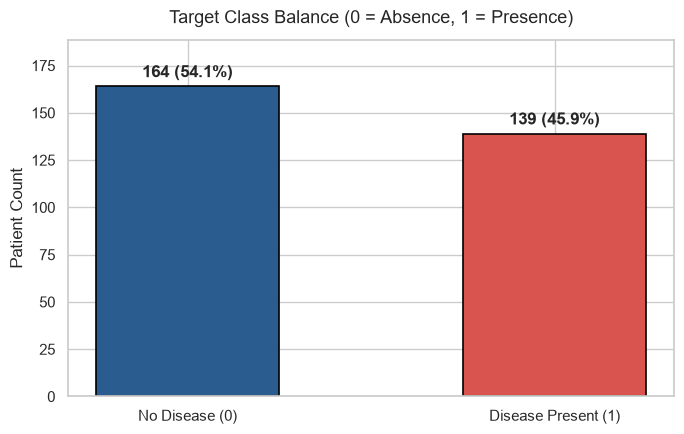

In [5]:
plt.figure(figsize=(7, 4.5))
counts = cleaned_df[BINARY_TARGET_COLUMN].value_counts().sort_index()
colors = ['#2b5c8f', '#d9534f']
bars = plt.bar(['No Disease (0)', 'Disease Present (1)'], counts.values, color=colors, width=0.5, edgecolor='black', linewidth=1.2)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 3, f'{yval} ({yval/len(cleaned_df):.1%})', ha='center', va='bottom', fontweight='bold')
plt.title('Target Class Balance (0 = Absence, 1 = Presence)', fontsize=13, pad=12)
plt.ylabel('Patient Count')
plt.ylim(0, max(counts.values) * 1.15)
plt.tight_layout()
plt.show()

### 5. Univariate Distributions of Clinical Biomarkers
Histograms with Kernel Density Estimation (KDE) overlays comparing distributions across disease status.

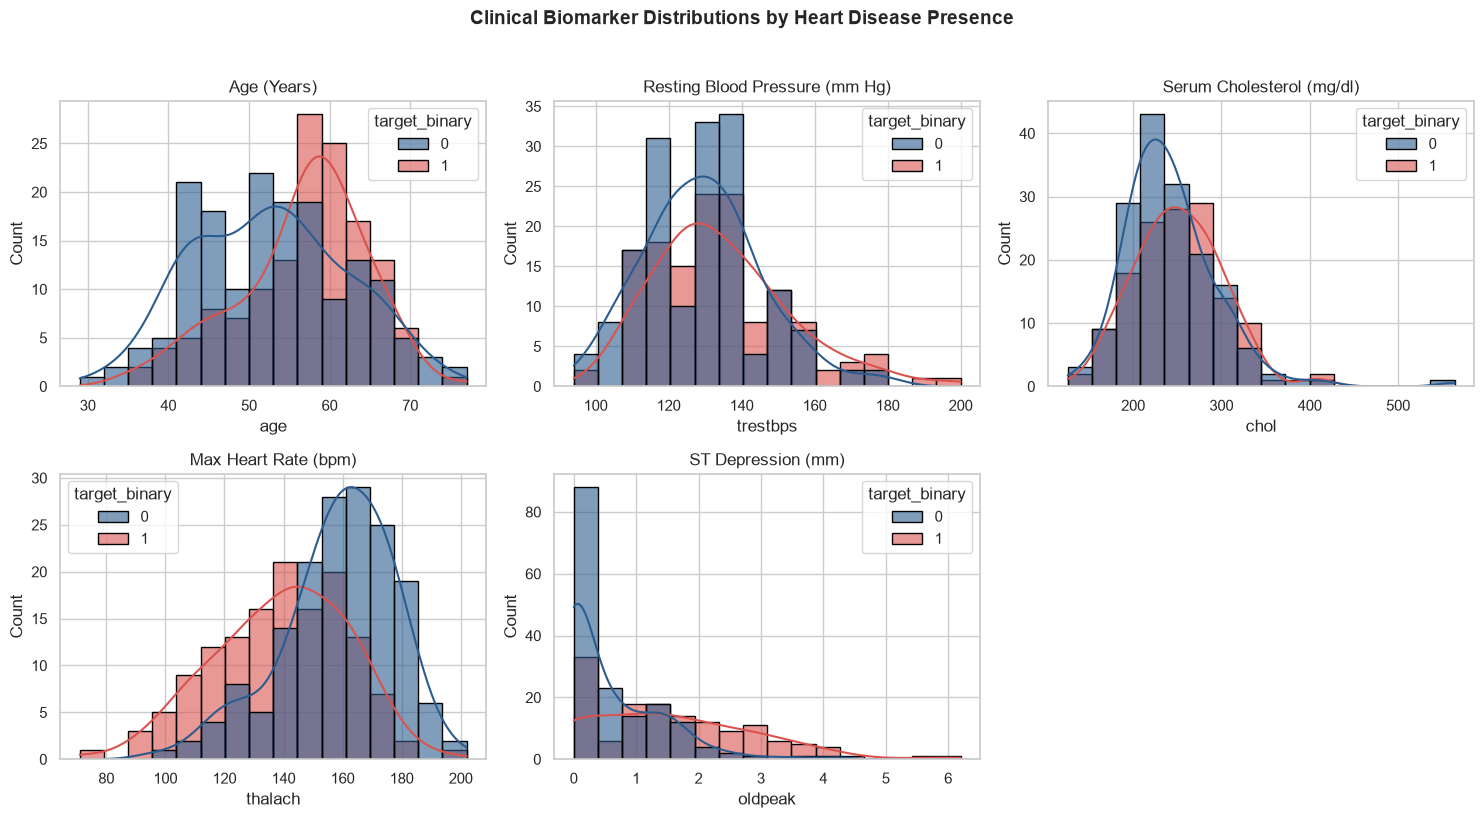

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
titles = {'age': 'Age (Years)', 'trestbps': 'Resting Blood Pressure (mm Hg)', 'chol': 'Serum Cholesterol (mg/dl)', 'thalach': 'Max Heart Rate (bpm)', 'oldpeak': 'ST Depression (mm)'}
for idx, feat in enumerate(NUMERICAL_FEATURES):
    sns.histplot(data=cleaned_df, x=feat, hue=BINARY_TARGET_COLUMN, kde=True, palette=['#2b5c8f', '#d9534f'], ax=axes[idx], bins=16, edgecolor='black', alpha=0.6)
    axes[idx].set_title(titles.get(feat, feat))
fig.delaxes(axes[5])
plt.suptitle('Clinical Biomarker Distributions by Heart Disease Presence', y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 6. Bivariate Clinical Risk Factor Analysis
Evaluating high-impact clinical indicators: Chest Pain Type (`cp`), Biological Sex (`sex`), and Exercise ST Slope (`slope`).

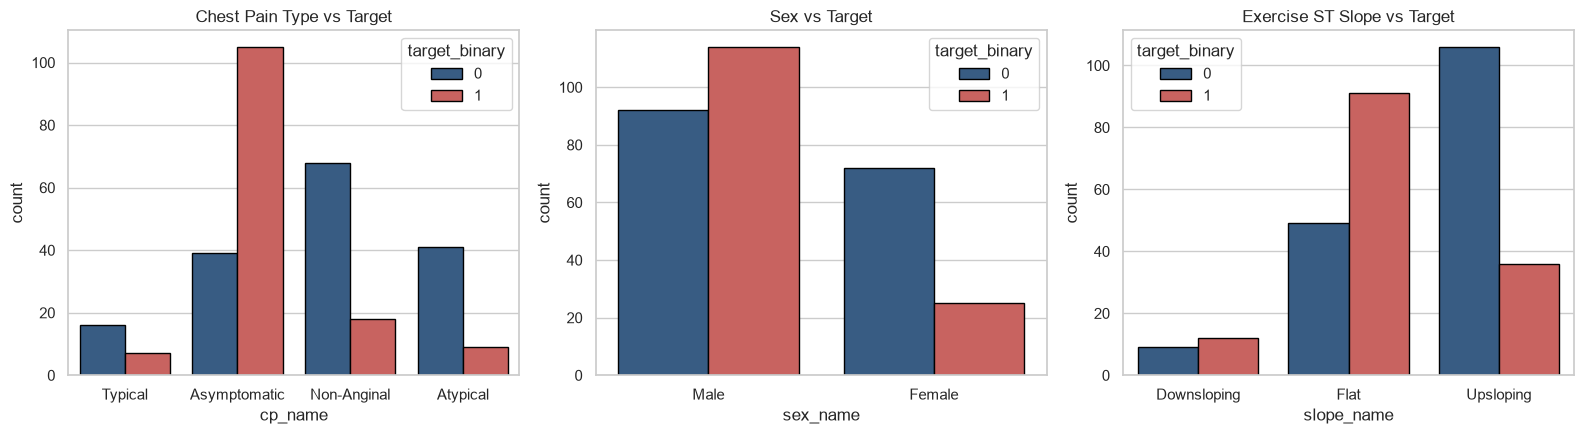

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
# Chest Pain Type
cp_df = cleaned_df.copy()
cp_df['cp_name'] = cp_df['cp'].map({1: 'Typical', 2: 'Atypical', 3: 'Non-Anginal', 4: 'Asymptomatic'})
sns.countplot(data=cp_df, x='cp_name', hue=BINARY_TARGET_COLUMN, palette=['#2b5c8f', '#d9534f'], ax=axes[0], edgecolor='black')
axes[0].set_title('Chest Pain Type vs Target')
# Sex
cp_df['sex_name'] = cp_df['sex'].map({0: 'Female', 1: 'Male'})
sns.countplot(data=cp_df, x='sex_name', hue=BINARY_TARGET_COLUMN, palette=['#2b5c8f', '#d9534f'], ax=axes[1], edgecolor='black')
axes[1].set_title('Sex vs Target')
# ST Slope
cp_df['slope_name'] = cp_df['slope'].map({1: 'Upsloping', 2: 'Flat', 3: 'Downsloping'})
sns.countplot(data=cp_df, x='slope_name', hue=BINARY_TARGET_COLUMN, palette=['#2b5c8f', '#d9534f'], ax=axes[2], edgecolor='black')
axes[2].set_title('Exercise ST Slope vs Target')
plt.tight_layout()
plt.show()

### 7. Correlation Matrix Heatmap
Examining pairwise linear correlations across all continuous and ordinal features.

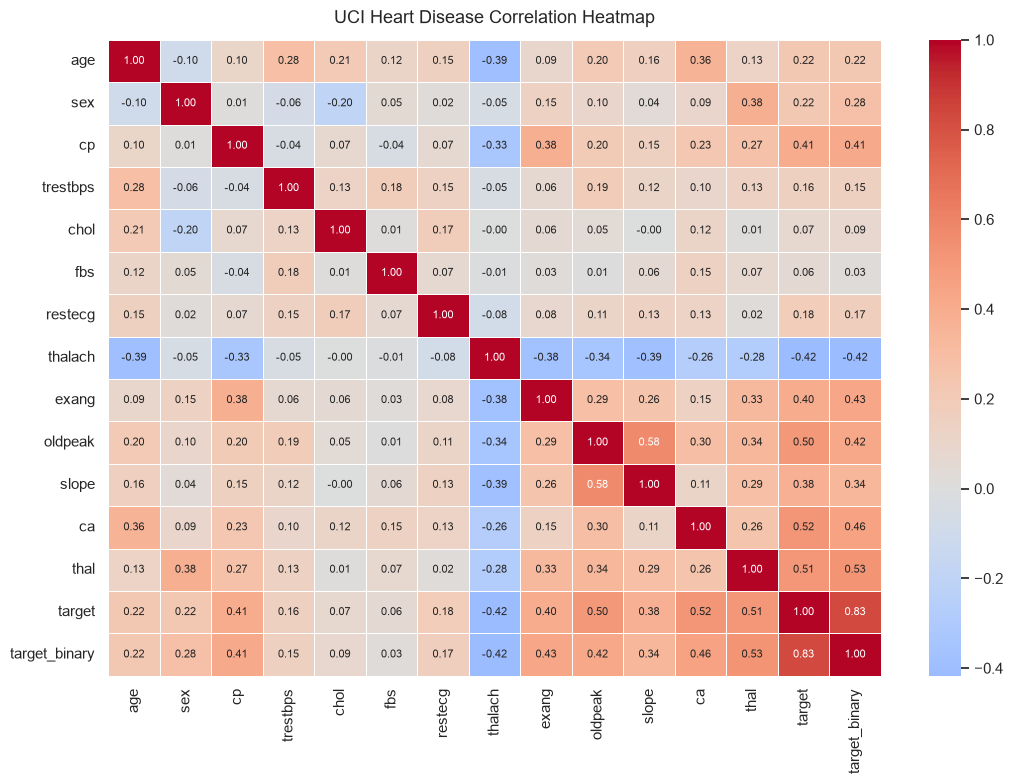

In [8]:
plt.figure(figsize=(11, 8))
corr = cleaned_df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.6, annot_kws={'size': 8})
plt.title('UCI Heart Disease Correlation Heatmap', fontsize=13, pad=12)
plt.tight_layout()
plt.show()

### 8. Key EDA Findings & Pipeline Implications
- **Class Equilibrium:** The 54.1% (negative) to 45.9% (positive) balance avoids the need for synthetic oversampling (SMOTE).
- **Strongest Predictive Features:** Chest pain type 4 (asymptomatic), low maximum heart rate (`thalach`), high exercise ST depression (`oldpeak`), and flat/downsloping ST segment (`slope`).
- **Preprocessing Requirements:** Median imputation for continuous variables; mode imputation and one-hot encoding for categorical variables; standard scaling for scale alignment.